# WiFi Demodulation

Edit **Editable settings**, then use **Run All** or execute cells from top to bottom. Metrics and plots appear directly below the code. The default is a synthetic 802.11a burst; set `capture` to a complex64 `.bin` or `.npy` file to analyze a recording.

In [10]:
%matplotlib inline
import os
from pathlib import Path

if os.name == "nt":
    packages = Path(os.environ["LOCALAPPDATA"]) / "Microsoft" / "WinGet" / "Packages"
    for runtime_dir in packages.glob("BrechtSanders.WinLibs.POSIX.UCRT_*/mingw64/bin"):
        os.environ["PATH"] = str(runtime_dir) + os.pathsep + os.environ.get("PATH", "")


## Imports and waveform helpers

In [11]:
"""WiFi scratch experiment: synthetic 802.11a or a complex64 capture."""

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

example_dir = Path(globals().get("__file__", Path.cwd() / "wifi_demod_pyscratch.py")).resolve().parent
for package_dir in (example_dir.parent, Path.cwd() / "nrdemod" / "python", Path.cwd() / "python", Path.cwd()):
    if (package_dir / "nrdemod" / "__init__.py").is_file():
        sys.path.insert(0, str(package_dir))
        break

from nrdemod import demod

FAMILIES = {
    "802.11a": demod.WIFI_A,
    "802.11b": demod.WIFI_B,
    "802.11n": demod.WIFI_N,
    "802.11ac": demod.WIFI_AC,
    "802.11ax": demod.WIFI_AX,
    "802.11be": demod.WIFI_BE,
}

STF_BINS = {-24: 1, -20: -1, -16: 1, -12: -1, -8: -1, -4: 1, 4: -1, 8: -1, 12: 1, 16: 1, 20: 1, 24: 1}
LTF = [1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, 1, 1,
       0, 1, -1, -1, 1, 1, -1, 1, -1, 1, -1, -1, -1, -1, -1, 1, 1, -1, -1, 1, -1, 1, -1, 1, 1, 1, 1]
PILOT_BINS = (-21, -7, 7, 21)
PILOT_BASE = (1, 1, 1, -1)
DATA_BINS = [index for index in range(-26, 27) if index != 0 and index not in PILOT_BINS]


def scrambler(seed: int, count: int) -> np.ndarray:
    state = [(seed >> index) & 1 for index in range(7)]
    output = np.empty(count, dtype=np.uint8)
    for index in range(count):
        output[index] = state[6] ^ state[3]
        state = [output[index]] + state[:-1]
    return output


def conv_encode(bits: np.ndarray) -> np.ndarray:
    register = 0
    output = []
    for bit in bits:
        register = (register >> 1) | (int(bit) << 6)
        output.append(bin(register & 0o133).count("1") & 1)
        output.append(bin(register & 0o171).count("1") & 1)
    return np.array(output, dtype=np.uint8)


def interleave_bpsk(bits: np.ndarray) -> np.ndarray:
    output = np.empty(48, dtype=np.uint8)
    for index in range(48):
        output[3 * (index % 16) + index // 16] = bits[index]
    return output


def ofdm_symbol(data_bpsk: np.ndarray, pilot_polarity: int) -> np.ndarray:
    grid = np.zeros(64, dtype=complex)
    grid[np.array(DATA_BINS) % 64] = data_bpsk
    grid[np.array(PILOT_BINS) % 64] = pilot_polarity * np.array(PILOT_BASE)
    time_domain = np.fft.ifft(grid) * 8
    return np.concatenate([time_domain[-16:], time_domain])


## Editable settings

In [12]:
capture = None
sample_rate = 20e6
family = "802.11a"
psdu_length = 100
cfo_hz = 5e3
snr_db = 35.0
leading_samples = 400
seed = 1


## Configure demodulator

In [13]:
cfg = demod.Config(sampleRate=sample_rate)


## Generate or load I/Q

In [14]:
if capture is None:
    if family != "802.11a" or sample_rate != 20e6:
        raise ValueError("Synthetic generation requires 802.11a at 20 MS/s; supply a capture for other settings")
    if not 1 <= psdu_length <= 4095:
        raise ValueError("PSDU length must be between 1 and 4095 bytes")
    rng = np.random.default_rng(seed)
    pilot_polarity = 1 - 2 * scrambler(0x7F, 127).astype(int)

    stf_grid = np.zeros(64, dtype=complex)
    for index, value in STF_BINS.items():
        stf_grid[index % 64] = value * (1 + 1j)
    stf_period = np.fft.ifft(stf_grid * np.sqrt(13 / 6)) * 8
    stf_iq = np.tile(stf_period, 3)[:160]

    ltf_grid = np.zeros(64, dtype=complex)
    ltf_grid[np.arange(-26, 27) % 64] = LTF
    ltf_period = np.fft.ifft(ltf_grid) * 8
    ltf_iq = np.concatenate([ltf_period[-32:], ltf_period, ltf_period])

    signal_bits = [1, 1, 0, 1, 0] + [(psdu_length >> index) & 1 for index in range(12)]
    signal_bits += [sum(signal_bits) & 1] + [0] * 6
    signal_coded = interleave_bpsk(conv_encode(np.array(signal_bits, dtype=np.uint8)))
    symbols = [ofdm_symbol(2.0 * signal_coded - 1.0, pilot_polarity[0])]

    num_symbols = -(-(16 + 8 * psdu_length + 6) // 24)
    data_bits = np.zeros(num_symbols * 24, dtype=np.uint8)
    data_bits[16:16 + 8 * psdu_length] = rng.integers(0, 2, 8 * psdu_length)
    data_bits ^= scrambler(0x5D, data_bits.size)
    tail_start = 16 + 8 * psdu_length
    data_bits[tail_start:tail_start + 6] = 0
    coded_bits = conv_encode(data_bits)
    for index in range(num_symbols):
        interleaved_bits = interleave_bpsk(coded_bits[48 * index:48 * (index + 1)])
        symbols.append(ofdm_symbol(2.0 * interleaved_bits - 1.0, pilot_polarity[(index + 1) % 127]))

    burst = np.concatenate([stf_iq, ltf_iq] + symbols)
    ideal_iq = (burst / np.sqrt(np.mean(np.abs(burst) ** 2))).astype(np.complex64)
    padded_iq = np.concatenate([np.zeros(leading_samples), ideal_iq, np.zeros(leading_samples)])
    shifted_iq = padded_iq * np.exp(2j * np.pi * cfo_hz * np.arange(padded_iq.size) / sample_rate)
    noise_rng = np.random.default_rng(2)
    noise_sigma = 10 ** (-snr_db / 20) / np.sqrt(2)
    noise = noise_sigma * (noise_rng.standard_normal(padded_iq.size) + 1j * noise_rng.standard_normal(padded_iq.size))
    iq = (shifted_iq + noise).astype(np.complex64)
else:
    capture_path = Path(capture)
    iq = np.load(capture_path).astype(np.complex64) if capture_path.suffix.lower() == ".npy" else np.fromfile(capture_path, dtype=np.complex64)
if iq.ndim != 1 or iq.size == 0:
    raise ValueError("Expected a nonempty one-dimensional complex I/Q capture")
print(f"{iq.size} samples at {sample_rate / 1e6:g} MS/s")


4000 samples at 20 MS/s


## Plot input I/Q

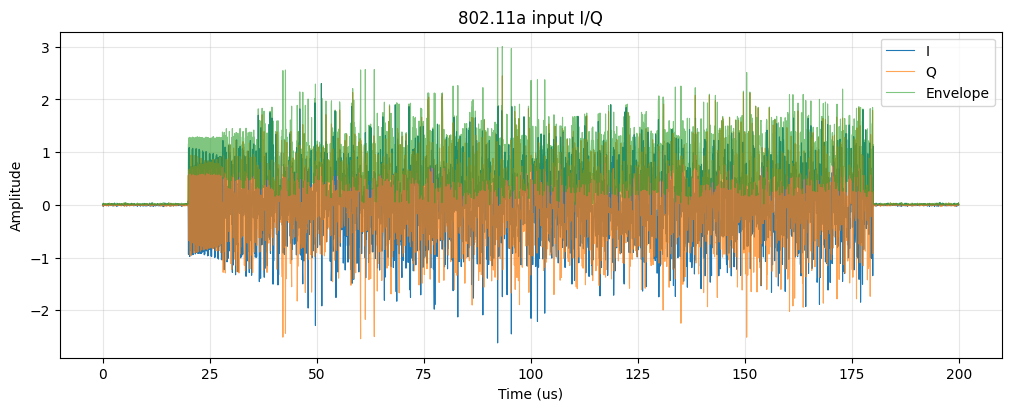

In [15]:
time_us = np.arange(iq.size) / sample_rate * 1e6
waveform_figure, waveform_axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
waveform_axis.plot(time_us, iq.real, label="I", linewidth=0.8)
waveform_axis.plot(time_us, iq.imag, label="Q", linewidth=0.8, alpha=0.7)
waveform_axis.plot(time_us, np.abs(iq), label="Envelope", linewidth=0.8, alpha=0.6)
waveform_axis.set(title=f"{family} input I/Q", xlabel="Time (us)", ylabel="Amplitude")
waveform_axis.legend()
waveform_axis.grid(True, alpha=0.3)
plt.show()


## Plot input spectrum

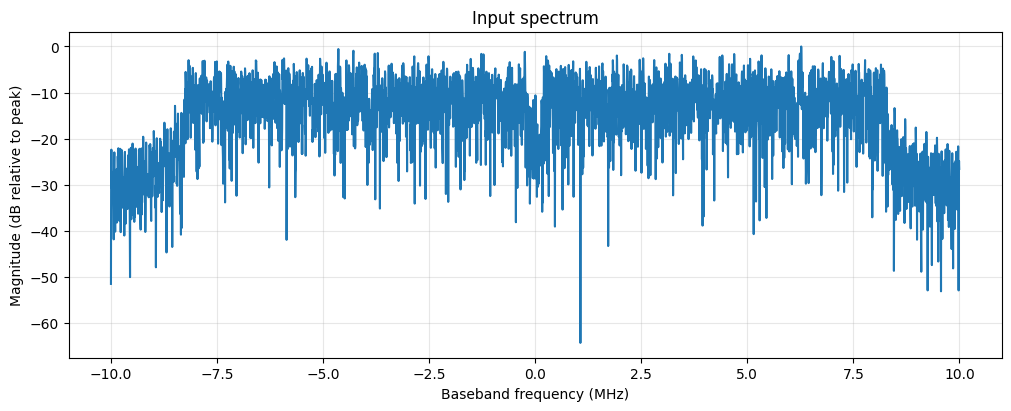

In [16]:
frequency_mhz = np.fft.fftshift(np.fft.fftfreq(iq.size, d=1 / sample_rate)) / 1e6
spectrum = np.abs(np.fft.fftshift(np.fft.fft(iq * np.hanning(iq.size))))
spectrum_db = 20 * np.log10(np.maximum(spectrum / max(float(spectrum.max()), 1e-12), 1e-12))
spectrum_figure, spectrum_axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
spectrum_axis.plot(frequency_mhz, spectrum_db)
spectrum_axis.set(title="Input spectrum", xlabel="Baseband frequency (MHz)", ylabel="Magnitude (dB relative to peak)")
spectrum_axis.grid(True, alpha=0.3)
plt.show()


## Demodulate and inspect metrics

In [17]:
res = demod.demodulate(FAMILIES[family], iq, cfg)
if not res.ok:
    raise RuntimeError(f"Demodulation failed: {res.error}")
metrics = res.as_dict()
for name, value in sorted(metrics.items()):
    print(f"{name:24s} {value}")
if not metrics.get("syncFound", True):
    raise RuntimeError("WiFi synchronization was not found")


burstFound               True
burstLength              3218
burstStart               401
codingRateDenominator    2
codingRateNumerator      1
dataRateMbps             6
error                    
family                   802.11a
frequencyErrorHz         5109.788414294652
modulation               0
numDataSymbols           35
ok                       True
peakEvmPercent           8.233791655163682
peakEvmSubcarrierIndex   36
peakEvmSymbolIndex       1
psduLengthBytes          100
rmsEvmPercent            3.5144744332697964
syncFound                True
syncRho                  0.9997568337970477
timingOffsetSamples      191


## Plot available EVM metrics

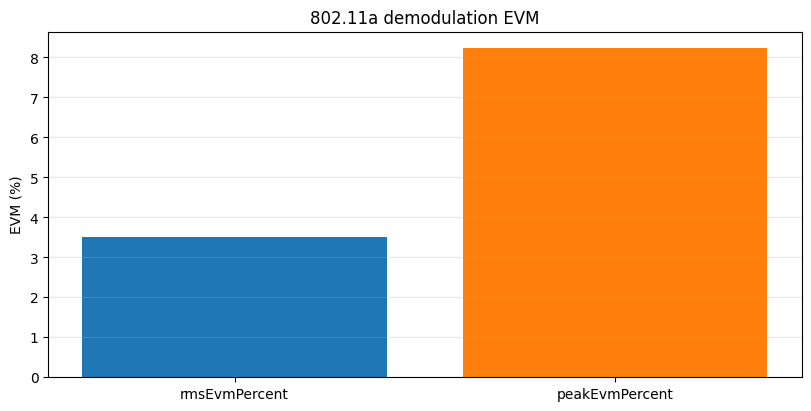

In [18]:
evm_names = [name for name in ("rmsEvmPercent", "peakEvmPercent", "dataRmsEvmPercent") if name in metrics]
if evm_names:
    evm_figure, evm_axis = plt.subplots(figsize=(8, 4), constrained_layout=True)
    evm_axis.bar(evm_names, [metrics[name] for name in evm_names], color=["tab:blue", "tab:orange", "tab:green"][:len(evm_names)])
    evm_axis.set(title=f"{family} demodulation EVM", ylabel="EVM (%)")
    evm_axis.grid(True, axis="y", alpha=0.3)
    plt.show()
else:
    print(f"{family} does not expose EVM metrics through this API")
